# Optimal Power flow

#### Parameter Definitions

In our data file, we have lots of values, and multiple sheets. Take a moment to make sure you understand what every parameter means, conceptually. Below you can find the relevant parameter definitions.

##### Node (i.e. Bus) Data
**Parameter Name** | **Description**
---|---
Vmax        | Maximal voltage of node
Vmin        | Minimal voltage of node
VAnglemax   | Maximal voltage angle of node
VAnglemin   | Minimal voltage angle of node
Pload       | Real power drawn by loads at node
Qload       | Reactive power drawn by loads at node
PGmax       | Maximal real power of generators at node
PGmin       | Minimal real power of generators at node
QGmax       | Maximal reactive power of generators at node
QGmin       | Minimal reactive power of generators at node
a           | Generator cost function first coefficient# a*p^2
b           | Generator cost function second coefficient# b*p
c           | Generator cost function third coefficient# c

where the cost function of a dispatchable generator at node $i$, with a generation power of $p_i$, is defined as

$$ C_i(p_i) = a_i p_i^2 + b_i p_i + c_i $$

subject to the power constraints $ P^{G,min}_i \le p_i \le P^{Gmax}_i $.

**Note**: The slack node, i.e. the reference node, serves as an angular reference for all other nodes in the system, and is thus set to 0 deg. At this slack node, the voltage magnitude is also assumed to be 1.0 p.u.

##### Admittance Matrices

To model the admittance between two buses, i and k, we have set up the following matrices.
One matrix is for the real part of the admittance, while the other is for the imaginary part.
Since these matrices cover all relationships between buses, these are square matrices.
An example for the structure of the Real Admittance Matrix is shown below:

$$\begin{bmatrix}
G_{1,1} & G_{1,2} & \dots & \dots & G_{1,n} \\
G_{2,1} & \ddots & & & \vdots \\
\vdots & & G_{i,k} & & \vdots \\
\vdots & & & \ddots & G_{n-1,n} \\
G_{n,1} & \dots & \dots & G_{n,n-1} & G_{n,n} 
\end{bmatrix}$$

**Knowledge Checkup:**
To make sure you understand the data structure, take a look at the data file(s) and see if you can answer the following conceptual questions:

1) How many buses are there in total? -> 5
2) Which buses have generators connected to them? -> 1,3,4
3) Which buses have loads connected to them? -> 4,5
4) Which one of these nodes is the slack node? -> 1

After you have answered these questions for yourself, you're all ready to code!

#### Dependency Setup

In [51]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from pyomo.environ import cos, sin
from opf_utils import solve_and_print, create_results_json

# Your email address (required for NEOS)
os.environ['NEOS_EMAIL'] = 'jonas.streuff@tum.de'
FILENAME = 'data//OPFData.xlsx'

### Test

In [16]:
test = pd.read_excel(FILENAME, sheet_name='NodeData')
test.head()

,Vmax,Vmin,VAnglemax,VAnglemin,Pload,Qload,PGmax,PGmin,QGmax,QGmin,a,b,c
0,1.00,1.00,0.000000,0.000000,0.000,0.000,1000.0,-1000.00,1000.0,-1000.0,0.0,0.35,0
1,1.05,0.95,3.141593,-3.141593,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.00,0
2,1.05,0.95,3.141593,-3.141593,0.000,0.000,0.4,0.10,0.3,-0.2,0.4,0.20,0
3,1.05,0.95,3.141593,-3.141593,0.900,0.400,0.4,0.05,0.2,-0.2,0.5,0.30,0
4,1.05,0.95,3.141593,-3.141593,0.239,0.129,0.0,0.00,0.0,0.0,0.0,0.00,0


#### Model Setup

In [17]:
def add_node_data(filename, m):
    # TODO: Load the pandas dataframes for the node data.
    # Hint: Pay attention to the file types and headers. 
    data = pd.read_excel(filename, sheet_name='NodeData')

    # TODO: Set the number of nodes
    m.nodes = pyo.Set(initialize=data.index.tolist())
    
    # TODO: Complete this function
    m.V_max = pyo.Param(m.nodes, initialize=data['Vmax'].to_dict())
    m.V_min = pyo.Param(m.nodes, initialize=data['Vmin'].to_dict())

    m.V_angle_max = pyo.Param(m.nodes, initialize=data['VAnglemax'].to_dict())
    m.V_angle_min = pyo.Param(m.nodes, initialize=data['VAnglemin'].to_dict())
    m.P_load = pyo.Param(m.nodes, initialize=data['Pload'].to_dict())
    m.Q_load = pyo.Param(m.nodes, initialize=data['Qload'].to_dict())

    m.P_G_max = pyo.Param(m.nodes, initialize=data['PGmax'].to_dict())
    m.P_G_min = pyo.Param(m.nodes, initialize=data['PGmin'].to_dict())
    
    m.Q_G_max = pyo.Param(m.nodes, initialize=data['QGmax'].to_dict())
    m.Q_G_min = pyo.Param(m.nodes, initialize=data['QGmin'].to_dict())

    m.a = pyo.Param(m.nodes, initialize=data['a'].to_dict())
    m.b = pyo.Param(m.nodes, initialize=data['b'].to_dict())
    m.c = pyo.Param(m.nodes, initialize=data['c'].to_dict())

    return m

def add_real_admittance_data(filename, m):
    # TODO: Load the pandas dataframes for the node data.
    # Hint: Pay attention to the file types and headers.
    data = pd.read_excel(filename, sheet_name='RealAdmittanceMatrix', header=None)
    assert data.shape[0] == data.shape[1], "The admittance data is not a square matrix"

    # TODO: Complete this function
    # We must flatten the dataframe to a dictionary for Pyomo initialization
    G_dict = {}
    rows, cols = data.shape
    for r in range(rows):
        for c in range(cols):
            G_dict[r, c] = data.iat[r, c]
    
    # Initialize the Parameter G indexed by (node, node)
    m.G = pyo.Param(m.nodes, m.nodes, initialize=G_dict)
    return m

def add_imag_admittance_data(filename, m):
    # TODO: Load the pandas dataframes for the node data.
    # Hint: Pay attention to the file types and headers.
    data = pd.read_excel(filename, sheet_name='ImaginaryAdmittanceMatrix', header=None)
    assert data.shape[0] == data.shape[1], "The admittance data is not a square matrix"

    # TODO: Complete this function
    # We must flatten the dataframe to a dictionary for Pyomo initialization
    
    B_dict = {}
    rows, cols = data.shape
    for r in range(rows):
        for c in range(cols):
            B_dict[r, c] = data.iat[r, c]

    m.B = pyo.Param(m.nodes, m.nodes, initialize=B_dict)

    return m

#### AC Optimal Power Flow Setup

In [18]:
def objective_rule(m):
    # TODO: Complete this function
    # Minimize sum of costs C_i(P_Gi) = a*P_Gi^2 + b*P_Gi + c
    return sum(
        m.a[i] * m.x_p[i]**2 + m.b[i] * m.x_p[i] + m.c[i]
        for i in m.nodes
    )

# TODO: Add functions for the AC OPF constraint rules, if necessary.
# Helper rules for linear constraints (inequalities)
def power_bounds_rule(m, i):
    # P_min <= P_G <= P_max
    return (m.P_G_min[i], m.x_p[i], m.P_G_max[i])

def reactive_power_bounds_rule(m, i):
    # Q_min <= Q_G <= Q_max
    return (m.Q_G_min[i], m.x_q[i], m.Q_G_max[i])

def voltage_bounds_rule(m, i):
    # V_min <= V <= V_max
    return (m.V_min[i], m.x_v[i], m.V_max[i])

def voltage_angle_bounds_rule(m, i):
    # delta_min <= delta <= delta_max
    return (m.V_angle_min[i], m.x_v_angle[i], m.V_angle_max[i])

def add_linear_constraints_ac(m):
    # TODO: Complete this function

    # Generator Real Power Limits
    m.power_bounds = pyo.Constraint(m.nodes, rule=power_bounds_rule)

    # Voltage Phase Angle Limits
    m.voltage_angle_bounds = pyo.Constraint(m.nodes, rule=voltage_angle_bounds_rule)

    # Generator Reactive Power Limits
    m.reactive_power_bounds = pyo.Constraint(m.nodes, rule=reactive_power_bounds_rule)

    # Bus Voltage Magnitude Limits
    m.voltage_bounds = pyo.Constraint(m.nodes, rule=voltage_bounds_rule)

    return m

# Helper rules for non-linear constraints (Power Balance)
def active_power_balance_rule(m, i):
    # P_i(V, delta) equation
    # P_flow_i = V_i * sum( V_k * (G_ik * cos(d_i - d_k) + B_ik * sin(d_i - d_k)))
    P_flow_i = m.x_v[i] * sum(
        m.x_v[k] * (
            m.G[i, k] * cos(m.x_v_angle[i] - m.x_v_angle[k]) + 
            m.B[i, k] * sin(m.x_v_angle[i] - m.x_v_angle[k])
        )
        for k in m.nodes
    )

    # p_G - P_L - P_flow = 0
    return m.x_p[i] - m.P_load[i] - P_flow_i == 0

def reactive_power_balance_rule(m, i):
    # Q_i(V, delta) equation
    # Q_flow_i = V_i * sum( V_k * (G_ik * sin(d_i - d_k) - B_ik * cos(d_i - d_k)) )
    Q_flow_i = m.x_v[i] * sum(
        m.x_v[k] * (
            m.G[i, k] * sin(m.x_v_angle[i] - m.x_v_angle[k]) - 
            m.B[i, k] * cos(m.x_v_angle[i] - m.x_v_angle[k])
        )
        for k in m.nodes
    )
    
    # Q_G - Q_L - Q_flow = 0
    return m.x_q[i] - m.Q_load[i] - Q_flow_i == 0

def add_nonlinear_constraints_ac(m):
    # TODO: Complete this function

    # Active Power Balance
    m.power_balance = pyo.Constraint(m.nodes, rule=active_power_balance_rule)

    # Reactive Power Balance
    m.reactive_power_balance = pyo.Constraint(m.nodes, rule=reactive_power_balance_rule)

    return m

#### DC Optimal Power Flow Setup

In [19]:
# TODO: Add functions for the DC OPF constraint rules, if necessary.

# Helper rules for DC Linear Constraints (Bounds)
def power_bounds_rule_dc(m, i):
    # P_min <= P_G <= P_max
    # Same as AC, but specific to the DC model setup
    return (m.P_G_min[i], m.x_p[i], m.P_G_max[i])

def voltage_angle_bounds_rule_dc(m, i):
    # delta_min <= delta <= delta_max
    # Same as AC but specific to the DC model setup
    return (m.V_angle_min[i], m.x_v_angle[i], m.V_angle_max[i])

# Helper rule for DC Power Balance 
def active_power_balance_rule_dc(m, i):
    # P_i(delta) = sum( B_ik * (delta_i - delta_k) )
    # Assumptions V=1.0, G=0, small angles 
    P_flow_i = sum(
        m.B[i, k] * (m.x_v_angle[i] - m.x_v_angle[k])
        for k in m.nodes
    )

    # P_G - P_L - P_flow = 0 
    return m.x_p[i] - m.P_load[i] - P_flow_i == 0

def add_linear_constraints_dc(m):
    # TODO: Complete this function, similar to add_linear_constraints_ac
    
    # Generator Active Power Limits
    m.power_bounds = pyo.Constraint(m.nodes, rule=power_bounds_rule_dc)
    
    # Voltage Angle Limits
    m.voltage_angle_bounds = pyo.Constraint(m.nodes, rule=voltage_angle_bounds_rule_dc)
    
    # Node: Voltage Magnitude and Reactive Power constraints are removed
    return m

def add_nonlinear_constraints_dc(m):
    # TODO: Complete this function, similar to add_nonlinear_constraints_ac
    # Note: The DC power flow equations are actually linear

    # Active Power Balance
    m.power_balance = pyo.Constraint(m.nodes, rule=active_power_balance_rule_dc)

    return m

##### Load Model from Data

In [20]:
# Loads the data from the given file into the model, defines the optimization problem, and returns the model at the end.
def load_model(filename, m, AC=True):
    # 1. Fill the model with the parameters from the files
    # Loading data from the excel sheets
    m = add_node_data(filename, m)
    m = add_real_admittance_data(filename, m)
    m = add_imag_admittance_data(filename, m)

    # 2. Define optimization variables
    
    # Active Power Generation 
    m.x_p = pyo.Var(m.nodes,
                    within=pyo.Reals,
                    doc='Optimization variable (power generation)')

    # Reactive Power Generation
    m.x_q = pyo.Var(m.nodes,
                    within=pyo.Reals,
                    doc='Optimization variable (reactive power generation)')
    
    # Voltage Magnitude (V)
    m.x_v = pyo.Var(m.nodes,
                    within=pyo.Reals,
                    doc='Optimization variable (voltage)')

    # Voltage Angle (delta)
    m.x_v_angle = pyo.Var(m.nodes,
                         within=pyo.Reals,
                         doc='Optimization variable (voltage angle)')
    
    # 3. Define objective function
    # Minimize sum of generator costs
    m.objective_function = pyo.Objective(
        rule=objective_rule,
        sense=pyo.minimize,
        doc='minimize(cost = sum of all generator operating costs)')
    
    # 4. Define the linear constraints
    if AC:
        m = add_linear_constraints_ac(m)
    else:
        # Added manually 
        for i in m.nodes:
            m.x_v[i].fix(1.0) # Voltage magnitude assumed 1.0 p.u.

        m = add_linear_constraints_dc(m)
    
    # Define the nonlinear constraints
    if AC:
        m = add_nonlinear_constraints_ac(m)
    else:
        # Added manually 
        for i in m.nodes:
            m.x_v[i].fix(1.0) # Voltage magnitude assumed 1.0 p.u.
            
        m = add_nonlinear_constraints_dc(m)

    return m

##### Solve AC Model

In [21]:
AC = True
model_ac = load_model(FILENAME, pyo.ConcreteModel(), AC)
solve_and_print(model_ac, AC)
# TODO: Uncomment if you want to write the result to json file
team_name = 'Group_B' 
create_results_json(model_ac, team_name, AC)

model.name="unknown";
    - termination condition: optimal
    - message from solver: CONOPT 4.36\x3a Locally optimal; objective
      0.4032767007444491; 7 iterations; evals\x3a nf = 8, ng = 7, nc = 50, nJ
      = 13, nH = 1, nHv = 10



Solution


Node		Voltage angle [deg]
1 		 0.0
2 		 -0.1479605917142426
3 		 -0.06511621773008298
4 		 -0.1622079660764928
5 		 -0.15284194533566098

Node		Voltage magnitude
1 		 1.0
2 		 0.9839069187431303
3 		 0.9652306188492912
4 		 0.9710647027190298
5 		 0.95

Node		Power
1 		 0.9451009564369689
2 		 0.0
3 		 0.19409263572233498
4 		 0.05666246887045961
5 		 0.0

Node		Reactive Power
1 		 0.6099494016115005
2 		 0.0
3 		 -0.08980595382293306
4 		 0.2
5 		 0.0

Cost:  0.4032767007444491
Results written to Group_B_AC.json


##### Solve DC Model

In [22]:
AC = False
model_dc = load_model(FILENAME, pyo.ConcreteModel(), AC)
solve_and_print(model_dc, AC)
# TODO: Uncomment if you want to write the result to json file
team_name = 'Group_B' 
create_results_json(model_dc, team_name, AC)




Solution


Node		Voltage angle [deg]
1 		 0.0
2 		 -0.1414593802110106
3 		 -0.06395843445725626
4 		 -0.1570625513306749
5 		 -0.1458868031946045

Node		Power
1 		 0.9015
2 		 0.0
3 		 0.1874999999999999
4 		 0.05
5 		 0.0

Cost:  0.3833374999999999
Results written to Group_B_DC.json


## Visualization

### Voltage Profile Plot

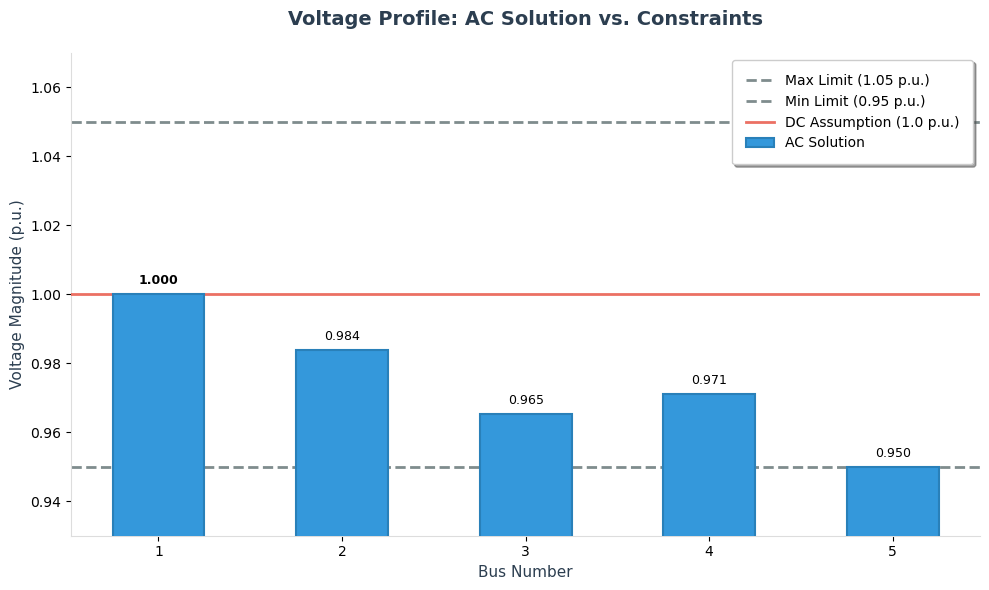

In [83]:
import matplotlib.pyplot as plt
import pyomo.environ as pyo
import numpy as np

def plot_voltage_profile_modern(model_ac):
    # --- 1. Data Extraction ---
    nodes = sorted(model_ac.nodes)
    display_ids = [n + 1 for n in nodes]
    
    # Extract values using Pyomo's value() function
    v_ac = [pyo.value(model_ac.x_v[n]) for n in nodes]
    v_min = [pyo.value(model_ac.V_min[n]) for n in nodes]
    v_max = [pyo.value(model_ac.V_max[n]) for n in nodes]
    
    # Create x-axis coordinates
    x = np.arange(len(nodes))

    # --- 2. Plot Setup (Modern Style) ---
    fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
    
    # Clean up the chart junk (spines)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#dddddd')
    ax.spines['bottom'].set_color('#dddddd')

    # --- 3. Draw Boundary Lines ---
    # Max Limit Line
    ax.axhline(max(v_max), color='#7f8c8d', linestyle='--', linewidth=2, zorder=1,
               label=f'Max Limit ({max(v_max)} p.u.)')
    
    # Min Limit Line
    ax.axhline(min(v_min), color='#7f8c8d', linestyle='--', linewidth=2, zorder=1,
               label=f'Min Limit ({min(v_min)} p.u.)')
    # --- 4. Plot DC Reference ---
    # A distinct red line for the DC assumption
    ax.axhline(1.0, color='#e74c3c', linestyle='-', linewidth=2, 
               label='DC Assumption (1.0 p.u.)', zorder=3, alpha=0.8)

    # --- 5. Plot AC Solution (Bars) ---
    # Use a modern blue with slight transparency and a solid edge
    bar_width = 0.5
    bars = ax.bar(x, v_ac, width=bar_width, color='#3498db', edgecolor='#2980b9', 
                  linewidth=1.5, label='AC Solution', zorder=4)

    # --- 6. Annotations and Limits ---
    # Smart y-limits to frame the data tightly but comfortably
    # We look for the lowest limit or value and subtract a margin
    y_min_data = min(min(v_min), min(v_ac))
    y_max_data = max(max(v_max), max(v_ac))
    ax.set_ylim(y_min_data - 0.02, y_max_data + 0.02)

    # Add text labels on top of bars
    for i, rect in enumerate(bars):
        height = rect.get_height()
        # Visual check: If the bar is practically 1.0, bold it to show it's the Slack Bus
        font_weight = 'bold' if abs(height - 1.0) < 1e-4 else 'normal'
        
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 5),  # 5 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight=font_weight,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7)) # legible background

    # --- 7. Final Polish ---
    ax.set_title('Voltage Profile: AC Solution vs. Constraints', fontsize=14, fontweight='bold', pad=20, color='#2c3e50')
    ax.set_ylabel('Voltage Magnitude (p.u.)', fontsize=11, color='#2c3e50')
    ax.set_xlabel('Bus Number', fontsize=11, color='#2c3e50')
    
    # Set x-ticks to match the Display IDs
    ax.set_xticks(x)
    ax.set_xticklabels(display_ids)
    
    # Custom Legend
    ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True, borderpad=1)
    
    plt.tight_layout()
    plt.show()

# Run with your solved model
plot_voltage_profile_modern(model_ac)

### Network Visualization

In [ ]:
def plot_grid_flow(model, AC=True):
    # 1. Setup the graph
    G = nx.DiGraph() # Directed graph for power flow

    # 2. Define Positions 
    # Node 1 is left, 2 top-mid, 3 bot-mid, 4 top-right, 5 bot-right
    pos = {
        0: (0, 1),
        1: (1, 2),
        2: (1, 0),
        3: (2, 2),
        4: (2, 0)
    }

    # 3. Add nodes
    # Color generators differently from pure Loads 
    # Based on data: Gen at 1,3,4. Load 4,5.
    node_colors = []
    node_info_labels = {}

    for n in sorted(model.nodes):
        G.add_node(n)
        
        p_gen = pyo.value(model.x_p[n])
        p_load = pyo.value(model.P_load[n])

        if AC and hasattr(model, 'x_q'):
            q_gen = pyo.value(model.x_q[n])
            q_load = pyo.value(model.Q_load[n])
        else:
            q_gen = 0.0
            q_load = 0.0

        if abs(p_gen) > 1e-3: # Tolerance for generation
            node_colors.append('#FF6B6B')
        else: 
            node_colors.append('#4ECDC4')

        node_info_labels[n] = (
            f"G: {p_gen:.2f}{q_gen:+.2f}j\n"
            f"L: {p_load:.2f}{q_load:+.2f}j"
        )

    # 4. Add edges and Calculate flows
    edge_labels = {}
    weights = []

    # List of branches 
    branches = [
        (1, 2),
        (1, 3),
        (2, 4),
        (3, 4),
        (3, 5),
        (4, 5)
    ]

    for (j, n) in branches:
        i = j - 1
        k = n - 1
        
        # 1. Get Exact AC Values
        vi = pyo.value(model.x_v_angle[i])
        vk = pyo.value(model.x_v_angle[k])
        Vm_i = pyo.value(model.x_v[i]) if AC else 1.0
        Vm_k = pyo.value(model.x_v[k]) if AC else 1.0
        
        # 2. Get Admittance Parameters (G and B)
        # Note: We need G (Conductance) for accurate AC flow
        try:
            g_ik = model.G[i, k]
            b_ik = model.B[i, k]
        except KeyError:
            g_ik = model.G[j, n]
            b_ik = model.B[j, n]

        # 3. Calculate Exact AC Active Power Flow (Source 90)
        # P_ik = Vi * Vk * (G * cos(delta) + B * sin(delta))
        delta = vi - vk
        
        # Calculate flow departing from node i
        p_flow_ik = Vm_i * Vm_k * (g_ik * np.cos(delta) + b_ik * np.sin(delta))
        
        # For direction, we check the sign. 
        # Note: In AC, P_ik does not exactly equal -P_ki due to losses!
        # We generally plot the direction of positive flow.
        flow = p_flow_ik

        if flow >= 0:
            u, v = i, k
        else:
            u, v = k, i
            flow = abs(flow)

        G.add_edge(u, v)
        edge_labels[(u, v)] = f"{flow:.3f}" # More precision
        weights.append(flow)

        print("[DEBUG] Branch ({},{}) | P_flow: {:.3f} from Node {} to Node {}".format(j, n, p_flow_ik, u+1, v+1))
        print("[DEBUG]   | G: {:.3f}, B: {:.3f}, delta: {:.3f} deg".format(g_ik, b_ik, delta))

    # 5. Draw
    plt.figure(figsize=(12, 9))
    plt.title(f"Optimal Power Flow ({'AC' if AC else 'DC'}) - Power Directions", fontsize=15)

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=800, edgecolors='black')

    # Draw labels 
    labels = {n: n + 1 for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels, font_color='white', font_weight='bold')

    # Create new positions shifted down by y - 0.25
    pos_info = {k: (v[0], v[1] - 0.25) for k, v in pos.items()}
    nx.draw_networkx_labels(G, pos_info, labels=node_info_labels, font_size=9, font_color='black')

    # Draw edges (arrows)
    nx.draw_networkx_edges(G, pos, width=2, arrowstyle='-|>', arrowsize=20, edge_color='gray')

    # Draw edge labels (Power Flow)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

    plt.ylim(-0.6, 2.5)
    plt.xlim(-0.5, 2.5)

    # Remove axis
    plt.axis('off')

    plt.tight_layout()
    plt.show()

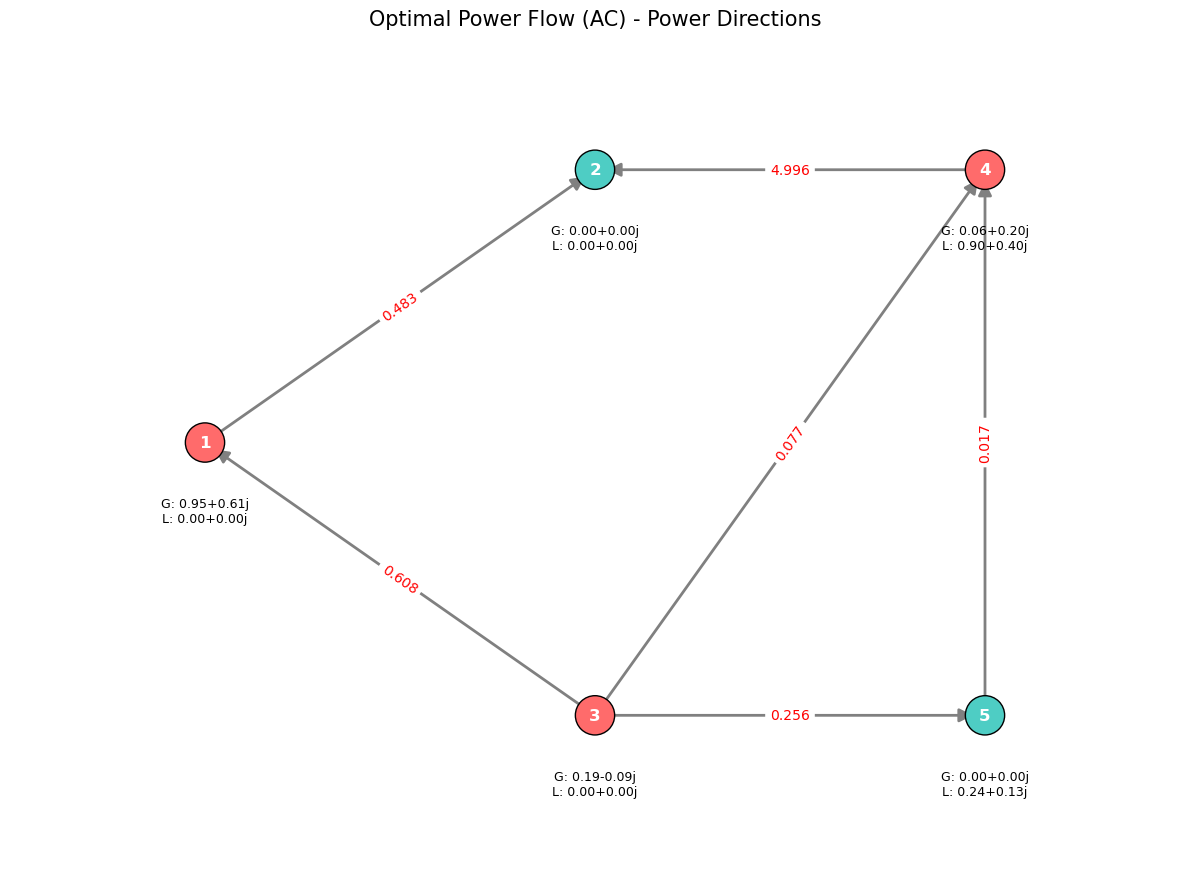

In [87]:
# Plot AC Power Flow
plot_grid_flow(model_ac, AC=True)

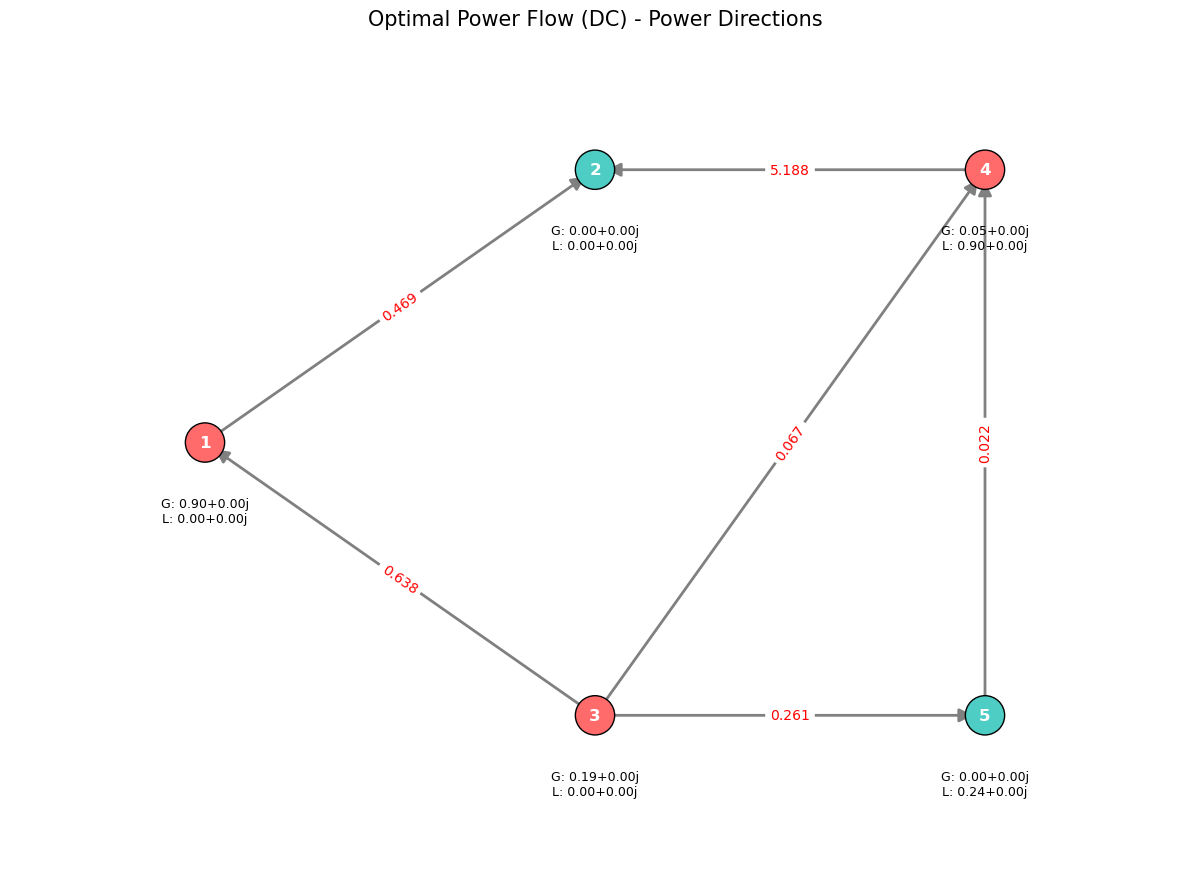

In [81]:
# Plot DC Power Flow
plot_grid_flow(model_dc, AC=False)